# FRED-MD Huber/L1 full CV with absolute Delta = 1

This experiment is the well-defined small-spacing limit requested after the
fractional search. `absolute_delta_n=1` is passed to the package CV helper,
so WERM uses a one-observation minimum segment length in every fold and the
full-data refit. This activates WERM's analytical-binomial marginal
approximation rather than silently collapsing nominal n/100 to the n/50
extrapolation-grid floor.

WERM segmentation and hard segment refits use Huber loss with epsilon 1.35.
Absolute loss is used only for held-out scoring. Every fold configuration
exhaustively selects over six L1 constants and `L=1,...,5` (0--4 change
points).

In [1]:
from pathlib import Path
import json
import os
import pickle
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from WERM.experiment_utils import weighted_erm_joint_cv

ROOT = Path.cwd()
DATA_PATH = ROOT / "FRED-MD data" / "fredmd_data.pkl"
RESULT_DIR = ROOT / "results" / "FRED-MD_huber-l1-absolute-delta1-cv"
FIGURE_DIR = ROOT / "figures" / "FRED-MD_huber-l1-absolute-delta1-cv"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
N_JOBS = min(36, os.cpu_count() or 1)

with DATA_PATH.open("rb") as handle:
    fred = pickle.load(handle)
X = np.asarray(fred["X"], dtype=float)
y = np.asarray(fred["y"], dtype=float).reshape(-1)
dates = np.asarray(fred["date"]).astype(str).reshape(-1)
n, p = X.shape
assert X.shape == (773, 114) and y.shape == (773,)

def absolute_loss(prediction, truth):
    return jnp.abs(prediction - truth)

def huber_loss(prediction, truth, epsilon=1.35):
    residual = prediction - truth
    absolute = jnp.abs(residual)
    return jnp.where(
        absolute <= epsilon,
        0.5 * jnp.square(residual),
        epsilon * (absolute - 0.5 * epsilon),
    )

CONSTANTS = (0.15, 0.3, 0.5, 0.75, 1.0, 2.0)
SEGMENT_COUNTS = (1, 2, 3, 4, 5)

In [2]:
records = []
for num_folds in (2, 3, 5):
    started = time.perf_counter()
    selected, cp, diagnostics = weighted_erm_joint_cv(
        X=X, y=y, M=huber_loss, M_scorer=absolute_loss,
        Lmax=5, delta_fraction=1/40, absolute_delta_n=1,
        l1_constants=CONSTANTS, num_folds=num_folds, n_jobs=N_JOBS,
        standardize_y=False, selection_strategy="exhaustive",
        return_diagnostics=True, penalty_norm="l1",
        segment_counts=SEGMENT_COUNTS,
    )
    candidates = [tuple(candidate) for candidate in diagnostics["candidates"]]
    scores = np.asarray(diagnostics["scores"], dtype=float)
    chosen_index = candidates.index(tuple(selected))
    baseline = min(
        score for candidate, score in zip(candidates, scores)
        if candidate[0] == 1
    )
    selected_score = float(scores[chosen_index])
    cp = np.asarray(cp, dtype=int).reshape(-1)
    record = {
        "loss": "Huber-eps1.35", "penalty_norm": "l1",
        "absolute_delta_n": 1, "num_folds": num_folds,
        "selected_segments": int(selected[0]),
        "selected_change_points": int(selected[0] - 1),
        "selected_constant": float(selected[1]),
        "estimated_change_points": cp.tolist(),
        "estimated_dates": dates[cp].tolist(),
        "selected_cv_mean": selected_score / n,
        "best_zero_cp_cv_mean": float(baseline / n),
        "relative_improvement_vs_zero_pct": float((baseline - selected_score) / baseline * 100),
        "candidate_scores": [
            {"segments": int(candidate[0]), "change_points": int(candidate[0] - 1),
             "constant": float(candidate[1]), "cv_total": float(score), "cv_mean": float(score / n)}
            for candidate, score in zip(candidates, scores)
        ],
        "elapsed_seconds": time.perf_counter() - started,
    }
    records.append(record)
    print(json.dumps({key: record[key] for key in (
        "num_folds", "selected_change_points", "selected_constant",
        "estimated_dates", "selected_cv_mean", "best_zero_cp_cv_mean",
        "relative_improvement_vs_zero_pct", "elapsed_seconds",
    )}, indent=2), flush=True)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
A

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


{
  "num_folds": 2,
  "selected_change_points": 0,
  "selected_constant": 0.15,
  "estimated_dates": [],
  "selected_cv_mean": 0.5384892550038032,
  "best_zero_cp_cv_mean": 0.5384892550038032,
  "relative_improvement_vs_zero_pct": 0.0,
  "elapsed_seconds": 37.075855791568756
}


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


{
  "num_folds": 3,
  "selected_change_points": 0,
  "selected_constant": 0.15,
  "estimated_dates": [],
  "selected_cv_mean": 0.5418964971058721,
  "best_zero_cp_cv_mean": 0.5418964971058721,
  "relative_improvement_vs_zero_pct": 0.0,
  "elapsed_seconds": 49.76534000504762
}


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


{
  "num_folds": 5,
  "selected_change_points": 1,
  "selected_constant": 0.15,
  "estimated_dates": [
    "1996-04"
  ],
  "selected_cv_mean": 0.5278472912660876,
  "best_zero_cp_cv_mean": 0.5287148694208456,
  "relative_improvement_vs_zero_pct": 0.1640918772926185,
  "elapsed_seconds": 79.5152835296467
}


In [3]:
summary = {
    "notebook": "FRED-MD Huber L1 Delta1 CV.ipynb",
    "loss_contract": {
        "segmentation": "Huber epsilon 1.35",
        "hard_segment_refits": "Huber epsilon 1.35",
        "heldout_scoring_only": "absolute_loss",
    },
    "absolute_delta_n": 1,
    "constants": list(CONSTANTS),
    "segment_counts": list(SEGMENT_COUNTS),
    "records": records,
}
summary_path = RESULT_DIR / "summary.json"
with summary_path.open("w") as handle:
    json.dump(summary, handle, indent=2)

table = pd.DataFrame([{
    "folds": record["num_folds"], "Delta_n": record["absolute_delta_n"],
    "C": record["selected_constant"],
    "selected CPs": record["selected_change_points"],
    "dates": ";".join(record["estimated_dates"]),
    "CV MAE": record["selected_cv_mean"],
    "zero-CP CV MAE": record["best_zero_cp_cv_mean"],
    "improvement (%)": record["relative_improvement_vs_zero_pct"],
} for record in records])
table.to_csv(RESULT_DIR / "selections.csv", index=False)
table

,folds,Delta_n,C,selected CPs,dates,CV MAE,zero-CP CV MAE,improvement (%)
0,2,1,0.15,0,,0.538489,0.538489,0.000000
1,3,1,0.15,0,,0.541896,0.541896,0.000000
2,5,1,0.15,1,1996-04,0.527847,0.528715,0.164092


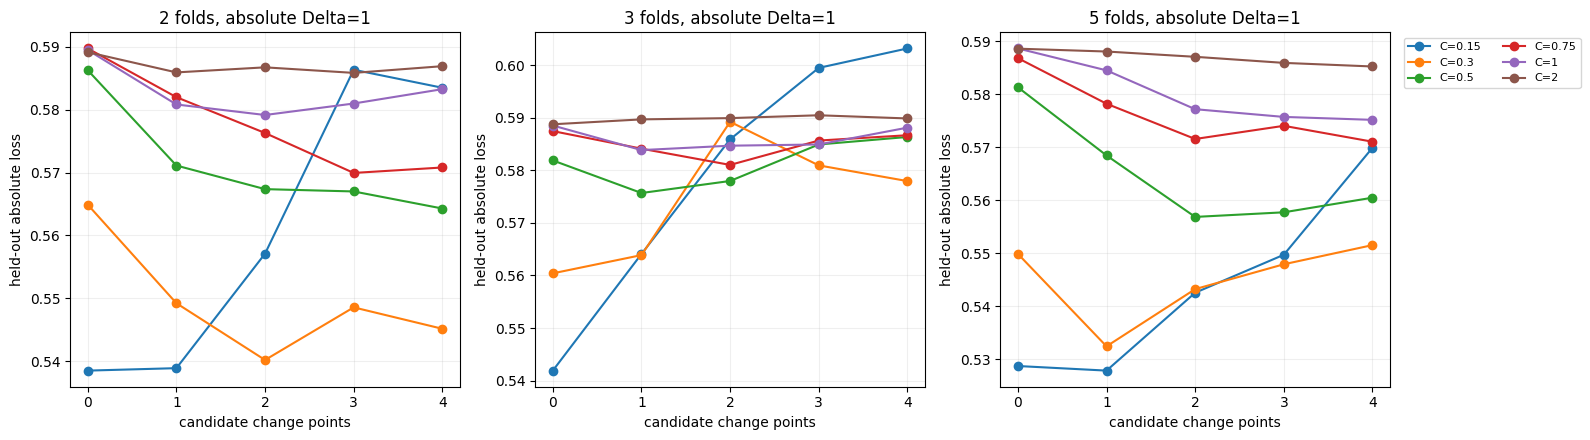

In [4]:
figure, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for axis, record in zip(axes, records):
    curve = pd.DataFrame(record["candidate_scores"])
    for constant, group in curve.groupby("constant"):
        axis.plot(group["change_points"], group["cv_mean"], marker="o", label=f"C={constant:g}")
    axis.set_title(f'{record["num_folds"]} folds, absolute Delta=1')
    axis.set_xlabel("candidate change points")
    axis.set_ylabel("held-out absolute loss")
    axis.set_xticks(range(5))
    axis.grid(alpha=0.2)
axes[-1].legend(fontsize=8, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "delta1_cv_surfaces.png", dpi=190, bbox_inches="tight")
plt.show()